# 5. Análisis bivariado (2.3)

Todo con el **entrenamiento**. Con decenas de miles de filas casi cualquier diferencia es
significativa, así que **cada prueba se acompaña de un tamaño de efecto** (ρ, ε², r biserial,
V de Cramér) y los p-valores se corrigen por comparaciones múltiples (Holm o Benjamini-Hochberg).

In [1]:
# Localiza la raíz del libro (la carpeta con _config.yml) para poder importar los módulos de src/
import sys
from pathlib import Path
raiz = Path.cwd().resolve()
while not (raiz / "_config.yml").exists():
    raiz = raiz.parent
sys.path.insert(0, str(raiz))
# Librerías de análisis y módulos propios: configuración, datos, EDA, evaluación y utilidades del libro
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from src import config as cfg, datos, eda, evaluacion as ev
from src.libro import md, tabla, mostrar_plotly
from src.eda import es, p_fmt
# Estilo común de los gráficos, semilla global (SEMILLA = 42) y formato de las tablas
eda.configurar_graficos()
cfg.fijar_semillas()
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)

In [2]:
# Datos de entrenamiento y versión con conteos en log1p para el análisis bivariado
from sklearn.feature_selection import mutual_info_regression
ev_, X, info, tr, gp, te = datos.panel_completo()
P = datos.panel_dataframe(X, info, tr)
fin_tr = datos.fecha_de_mes(info["m_test"] - cfg.GAP_MESES)[0]
cat_tr = ev_[ev_.time < fin_tr].copy()
conteos = [c for c in X.columns if c.startswith(("n_", "n35", "vec", "n_mismo"))]
L = P.copy()
L[conteos] = np.log1p(L[conteos])

## 5.1 Numéricas vs numéricas: dispersión y correlación

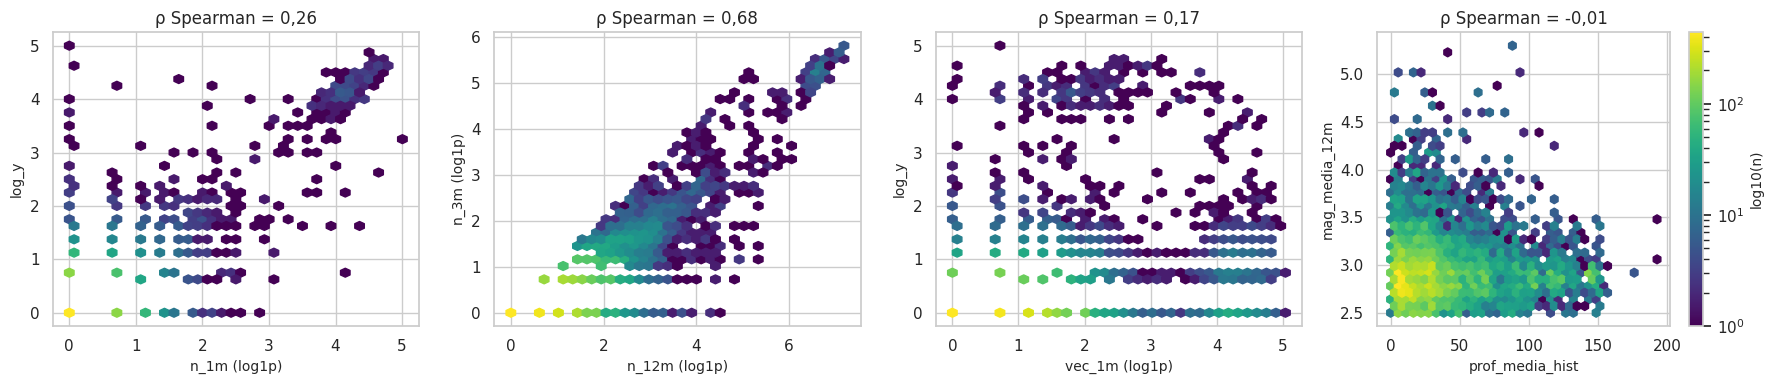

In [3]:
# Diagramas hexbin de los pares de variables más relevantes
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
pares = [("n_1m", "log_y"), ("n_12m", "n_3m"), ("vec_1m", "log_y"), ("prof_media_hist", "mag_media_12m")]
for ax, (a, b) in zip(axes, pares):
    d = L[[a, b]].dropna()
    hb = ax.hexbin(d[a], d[b], gridsize=35, bins="log", cmap="viridis", mincnt=1)
    ax.set_xlabel(a + (" (log1p)" if a in conteos else "")); ax.set_ylabel(b + (" (log1p)" if b in conteos else ""))
    ax.set_title(f"ρ Spearman = {es(stats.spearmanr(d[a], d[b])[0], 2)}")
plt.colorbar(hb, ax=axes[-1], label="log10(n)")
plt.tight_layout(); eda.guardar_figura(fig, "05_hexbin.png"); plt.show()

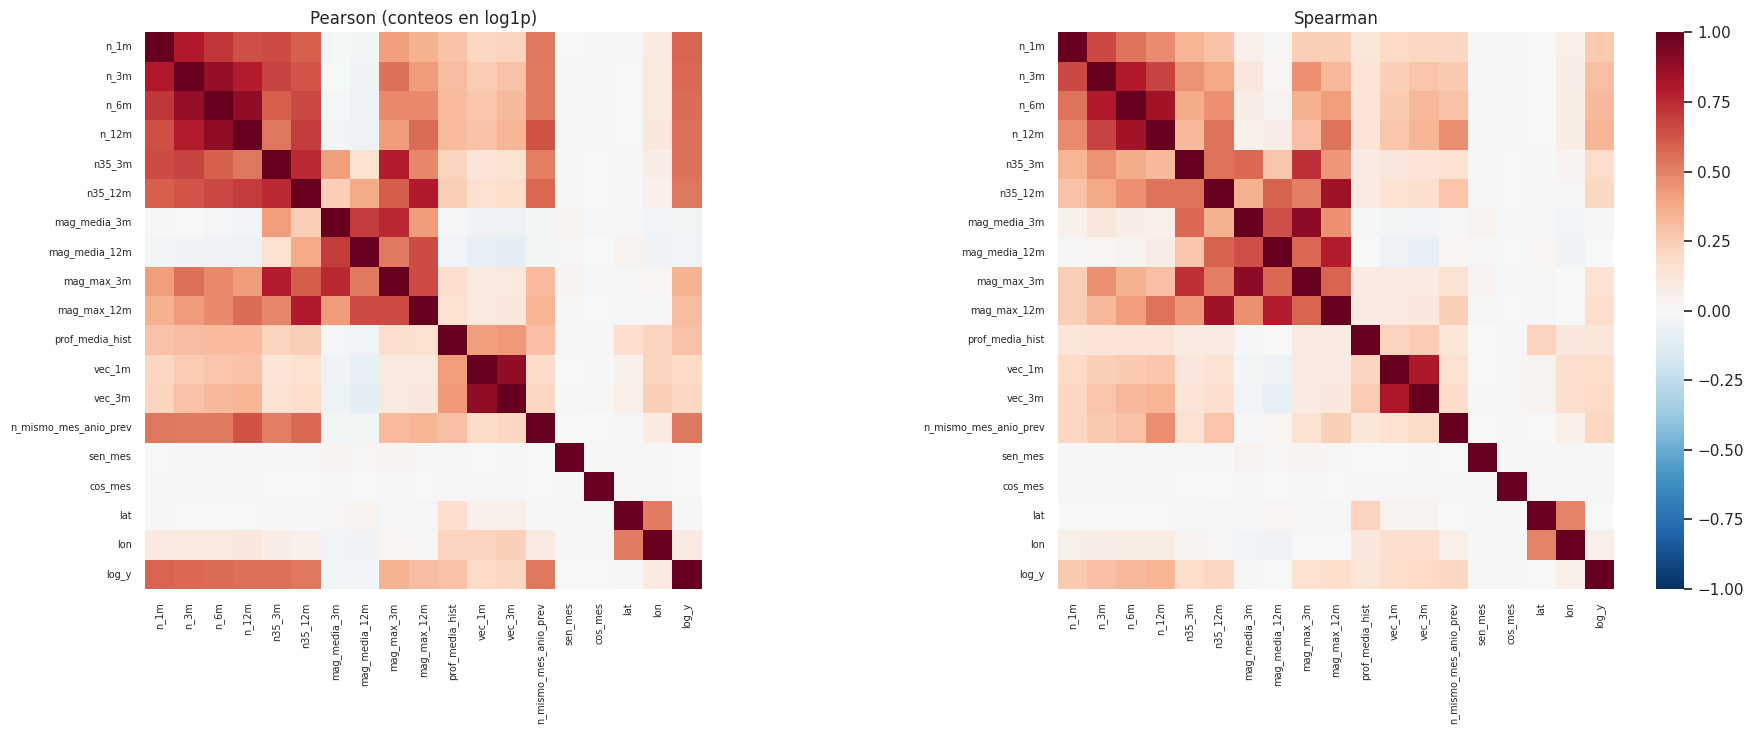

,var_1,var_2,rho
94,mag_media_3m,mag_max_3m,0.897
83,n35_12m,mag_max_12m,0.847
35,n_6m,n_12m,0.837
143,vec_1m,vec_3m,0.810
18,n_3m,n_6m,0.803


In [4]:
# Matrices de correlación de Pearson (conteos en log1p) y Spearman
cols = list(X.columns) + ["log_y"]
pear = L[cols].corr(method="pearson")
spear = L[cols].corr(method="spearman")
eda.guardar_tabla(spear.reset_index(), "correlacion_spearman.csv")
fig, axes = plt.subplots(1, 2, figsize=(19, 7.5))
for ax, M, t in ((axes[0], pear, "Pearson (conteos en log1p)"), (axes[1], spear, "Spearman")):
    sns.heatmap(M, cmap="RdBu_r", vmin=-1, vmax=1, ax=ax, cbar=ax is axes[1], square=True, xticklabels=True, yticklabels=True)
    ax.set_title(t); ax.tick_params(labelsize=7)
plt.tight_layout(); eda.guardar_figura(fig, "05_correlaciones.png"); plt.show()
alto = (spear.where(np.triu(np.ones(spear.shape, bool), 1)).stack().rename("rho").reset_index()
        .rename(columns={"level_0": "var_1", "level_1": "var_2"}))
alto = alto[alto.rho.abs() >= 0.8].sort_values("rho", key=np.abs, ascending=False)
alto.round(3)

In [5]:
md(f"""**Interpretación.**
- **Bloques redundantes.** Hay {len(alto)} pares con |ρ| ≥ 0,8, todos dentro de bloques que miden lo mismo a distintas escalas:
  - los conteos de la propia celda (`n_1m` … `n_12m`, `n35_*`);
  - los de la vecindad (`vec_1m`, `vec_3m`);
  - las magnitudes de ventana (media y máxima).
- **Relación con el objetivo.** Es **monótona pero no lineal**: en el hexbin la nube de `n_1m` contra log(1 + y) tiene forma de
  embudo, con mucha masa en (0, 0) y una relación casi lineal solo en las celdas activas. Por eso Spearman y Pearson-en-log
  difieren poco y ambos son adecuados.
- **Redundancia.** Se cuantifica con el VIF (sección 5.5).""")

**Interpretación.**
- **Bloques redundantes.** Hay 5 pares con |ρ| ≥ 0,8, todos dentro de bloques que miden lo mismo a distintas escalas:
  - los conteos de la propia celda (`n_1m` … `n_12m`, `n35_*`);
  - los de la vecindad (`vec_1m`, `vec_3m`);
  - las magnitudes de ventana (media y máxima).
- **Relación con el objetivo.** Es **monótona pero no lineal**: en el hexbin la nube de `n_1m` contra log(1 + y) tiene forma de
  embudo, con mucha masa en (0, 0) y una relación casi lineal solo en las celdas activas. Por eso Spearman y Pearson-en-log
  difieren poco y ambos son adecuados.
- **Redundancia.** Se cuantifica con el VIF (sección 5.5).

## 5.2 Categóricas vs numéricas: comparación entre grupos

- **Objetivo según el mes calendario.** ¿Hay estacionalidad? Prueba de Kruskal-Wallis con su tamaño
  de efecto ε².
- **Objetivo según si la celda tuvo actividad el mes anterior (`n_1m` > 0).** Prueba de Mann-Whitney
  con su tamaño de efecto: la correlación biserial de rangos.
- **Magnitud y profundidad según el departamento** (en el catálogo). Kruskal-Wallis con ε².

Se usan pruebas no paramétricas porque ninguna variable es normal (capítulo 4).

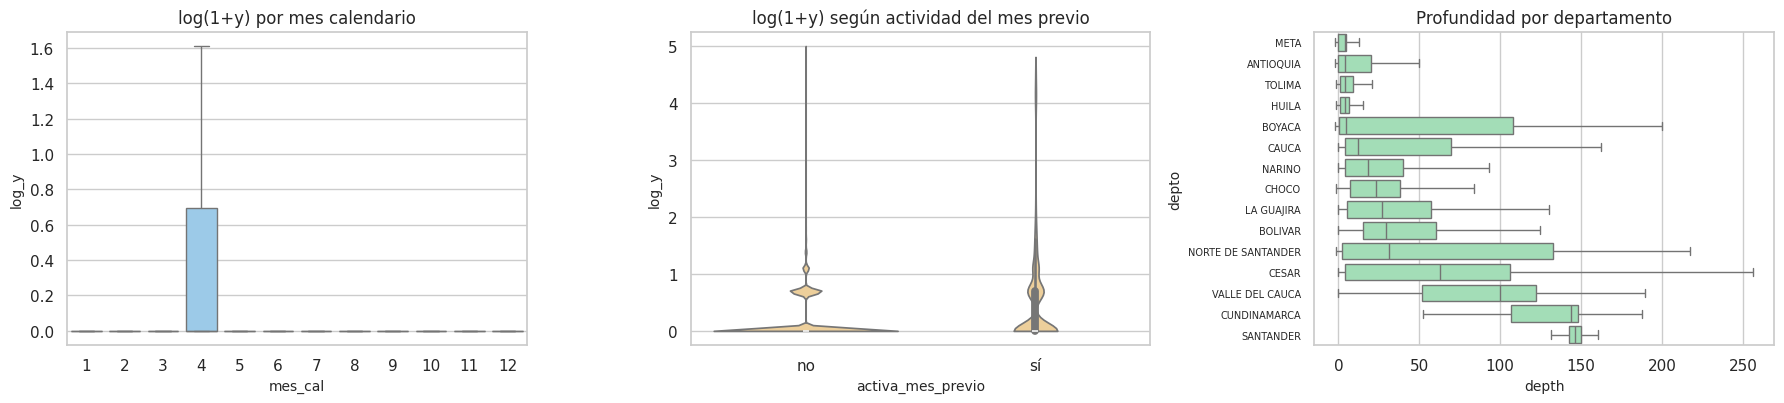

,relación,prueba,estadístico,p,efecto,tamaño,p_Holm
0,y ~ mes calendario,Kruskal-Wallis,1.409550e+01,0.2278,ε²,0.0005,0.2278
1,y ~ celda activa el mes previo,Mann-Whitney,1.074868e+08,0.0000,r biserial,0.2382,0.0000
2,mag ~ departamento (15 con ≥ 200 sismos),Kruskal-Wallis,1.487251e+02,0.0000,ε²,0.0052,0.0000
3,depth ~ departamento (15 con ≥ 200 sismos),Kruskal-Wallis,1.778912e+04,0.0000,ε²,0.6262,0.0000


In [6]:
# Objetivo frente a variables categóricas: Kruskal-Wallis / Mann-Whitney con tamaño del efecto y corrección de Holm
P["mes_cal"] = P.fecha_obj.dt.month
P["activa_mes_previo"] = np.where(P.n_1m > 0, "sí", "no")
deps = cat_tr.depto.value_counts()
deps = deps[deps >= 200].index
filas = []
g = [grp.y.to_numpy() for _, grp in P.groupby("mes_cal")]
h, p = stats.kruskal(*g); filas.append(("y ~ mes calendario", "Kruskal-Wallis", h, p, "ε²", eda.epsilon_cuadrado(h, len(P))))
a, b = P.loc[P.n_1m > 0, "y"], P.loc[P.n_1m == 0, "y"]
u, p = stats.mannwhitneyu(a, b); filas.append(("y ~ celda activa el mes previo", "Mann-Whitney", u, p, "r biserial", -eda.biserial_rangos(u, len(a), len(b))))
for v in ("mag", "depth"):
    g = [cat_tr.loc[cat_tr.depto == d, v].to_numpy() for d in deps]
    h, p = stats.kruskal(*g); filas.append((f"{v} ~ departamento ({len(deps)} con ≥ 200 sismos)", "Kruskal-Wallis", h, p, "ε²", eda.epsilon_cuadrado(h, sum(map(len, g)))))
grupos = pd.DataFrame(filas, columns=["relación", "prueba", "estadístico", "p", "efecto", "tamaño"])
grupos["p_Holm"] = eda.holm(grupos.p)
eda.guardar_tabla(grupos, "comparacion_grupos.csv")
fig, axes = plt.subplots(1, 3, figsize=(18, 4.2))
sns.boxplot(data=P, x="mes_cal", y="log_y", ax=axes[0], color="#90cdf4", showfliers=False); axes[0].set_title("log(1+y) por mes calendario")
sns.violinplot(data=P, x="activa_mes_previo", y="log_y", ax=axes[1], color="#fbd38d", cut=0); axes[1].set_title("log(1+y) según actividad del mes previo")
orden = cat_tr[cat_tr.depto.isin(deps)].groupby("depto").depth.median().sort_values().index
sns.boxplot(data=cat_tr[cat_tr.depto.isin(deps)], y="depto", x="depth", order=orden, ax=axes[2], color="#9ae6b4", showfliers=False)
axes[2].set_title("Profundidad por departamento"); axes[2].tick_params(axis="y", labelsize=7)
plt.tight_layout(); eda.guardar_figura(fig, "05_grupos.png"); plt.show()
grupos.round(4)

In [7]:
gr = grupos.set_index("relación")
md(f"""**Interpretación.**
- **Mes calendario.** No es significativo (p de Holm = {p_fmt(gr.iloc[0]['p_Holm'])}) y el efecto es **despreciable**
  (ε² = {es(gr.iloc[0]['tamaño'], 4)}): no hay estacionalidad en el conteo.
- **Actividad del mes previo.** Efecto **moderado** (biserial de rangos = {es(gr.iloc[1]['tamaño'], 2)}): las celdas que tuvieron sismos el mes
  anterior tienden a tener más el mes siguiente. Es la **persistencia** que explotan las líneas base y los modelos.
- **Departamento.** Explica una parte grande de la profundidad (ε² = {es(gr.iloc[3]['tamaño'], 2)}): Santander concentra los sismos
  intermedios del nido y la costa pacífica los superficiales. La magnitud, en cambio, difiere poco entre departamentos
  (ε² = {es(gr.iloc[2]['tamaño'], 3)}).
- **Lectura conjunta.** Estos resultados ilustran la advertencia del enunciado: la magnitud por departamento tiene un p-valor
  minúsculo pero un efecto irrelevante. Solo dos efectos (actividad previa y profundidad por departamento) importan en la práctica.""")

**Interpretación.**
- **Mes calendario.** No es significativo (p de Holm = 0,228) y el efecto es **despreciable**
  (ε² = 0,0005): no hay estacionalidad en el conteo.
- **Actividad del mes previo.** Efecto **moderado** (biserial de rangos = 0,24): las celdas que tuvieron sismos el mes
  anterior tienden a tener más el mes siguiente. Es la **persistencia** que explotan las líneas base y los modelos.
- **Departamento.** Explica una parte grande de la profundidad (ε² = 0,63): Santander concentra los sismos
  intermedios del nido y la costa pacífica los superficiales. La magnitud, en cambio, difiere poco entre departamentos
  (ε² = 0,005).
- **Lectura conjunta.** Estos resultados ilustran la advertencia del enunciado: la magnitud por departamento tiene un p-valor
  minúsculo pero un efecto irrelevante. Solo dos efectos (actividad previa y profundidad por departamento) importan en la práctica.

## 5.3 Categóricas vs categóricas: contingencia, χ² y V de Cramér

In [8]:
# Asociación entre categóricas del catálogo: chi-cuadrado y V de Cramér
cat_tr["clase_mag"] = pd.cut(cat_tr.mag, [2.5, 3.0, 3.5, 4.5, 10], right=False, labels=["2,5–3", "3–3,5", "3,5–4,5", "≥ 4,5"])
cat_tr["clase_prof"] = pd.cut(cat_tr.depth, [-10, 30, 70, 300, 800], labels=["superficial < 30", "30–70", "intermedia 70–300", "profunda > 300"])
cat_tr["portal"] = np.where(cat_tr.time < "2018-03-01", "histórico", "actual")
cat_tr["depto_g"] = cat_tr.depto.where(cat_tr.depto.isin(deps), "OTROS")
filas = []
for a, b in (("depto_g", "clase_prof"), ("depto_g", "clase_mag"), ("clase_prof", "clase_mag"), ("portal", "clase_mag")):
    v, chi2, p = eda.cramers_v(cat_tr[a], cat_tr[b])
    filas.append({"par": f"{a} × {b}", "chi2": chi2, "p": p, "V_Cramer": v})
cc = pd.DataFrame(filas)
cc["p_Holm"] = eda.holm(cc.p)
eda.guardar_tabla(cc, "cramer_pares.csv")
display(pd.crosstab(cat_tr.clase_prof, cat_tr.clase_mag, normalize="index").round(3))
cc.round(4)

clase_mag,"2,5–3","3–3,5","3,5–4,5","≥ 4,5"
clase_prof,,,,
superficial < 30,0.632,0.238,0.117,0.013
30–70,0.595,0.249,0.139,0.016
intermedia 70–300,0.648,0.232,0.108,0.012
profunda > 300,0.500,0.000,0.250,0.250


,par,chi2,p,V_Cramer,p_Holm
0,depto_g × clase_prof,25174.0860,0.0000,0.5341,0.0000
1,depto_g × clase_mag,202.3964,0.0000,0.0423,0.0000
2,clase_prof × clase_mag,52.5968,0.0000,0.0222,0.0000
3,portal × clase_mag,14.7253,0.0021,0.0200,0.0021


In [9]:
md(f"""**Interpretación.**
- **Departamento × profundidad.** V = {es(cc.V_Cramer[0], 2)}: asociación **fuerte**, que repite el hallazgo anterior (la geografía tectónica
  determina la profundidad).
- **Profundidad × magnitud.** V = {es(cc.V_Cramer[2], 2)}: prácticamente independientes. Las proporciones por clase de magnitud son
  casi iguales en cada clase de profundidad (tabla de contingencia normalizada por fila). La única fila distinta, «profunda > 300»,
  tiene muy pocos sismos.
- **Portal × magnitud.** V = {es(cc.V_Cramer[3], 2)}. Si el cambio de portal hubiera alterado mucho la escala de magnitud, esta
  asociación sería grande; su valor bajo apoya que la mezcla de escalas no distorsiona seriamente la distribución de magnitudes
  (capítulo 2).""")

**Interpretación.**
- **Departamento × profundidad.** V = 0,53: asociación **fuerte**, que repite el hallazgo anterior (la geografía tectónica
  determina la profundidad).
- **Profundidad × magnitud.** V = 0,02: prácticamente independientes. Las proporciones por clase de magnitud son
  casi iguales en cada clase de profundidad (tabla de contingencia normalizada por fila). La única fila distinta, «profunda > 300»,
  tiene muy pocos sismos.
- **Portal × magnitud.** V = 0,02. Si el cambio de portal hubiera alterado mucho la escala de magnitud, esta
  asociación sería grande; su valor bajo apoya que la mezcla de escalas no distorsiona seriamente la distribución de magnitudes
  (capítulo 2).

## 5.4 Predictoras vs objetivo: Spearman e información mutua

La información mutua (MI) captura también relaciones no lineales y no monótonas. Se estima con
`mutual_info_regression` (k = 3 vecinos) sobre una submuestra de 15.000 filas del entrenamiento.
Las magnitudes faltantes se imputan con la mediana de entrenamiento solo para este cálculo.

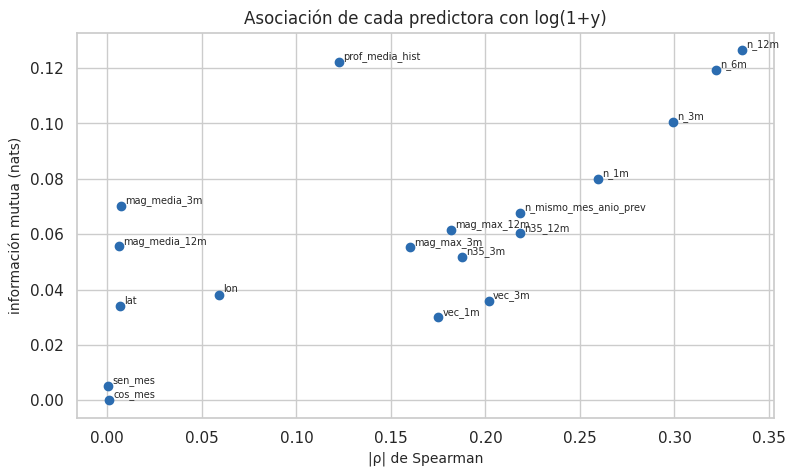

,variable,Spearman_rho,p,info_mutua,p_FDR
3,n_12m,0.3360,0.0000,0.1264,0.0000
10,prof_media_hist,0.1223,0.0000,0.1222,0.0000
2,n_6m,0.3221,0.0000,0.1194,0.0000
1,n_3m,0.2993,0.0000,0.1007,0.0000
0,n_1m,0.2593,0.0000,0.0801,0.0000
6,mag_media_3m,0.0074,0.3642,0.0701,0.4098
13,n_mismo_mes_anio_prev,0.2184,0.0000,0.0676,0.0000
9,mag_max_12m,0.1818,0.0000,0.0616,0.0000
5,n35_12m,0.2182,0.0000,0.0603,0.0000
7,mag_media_12m,-0.0059,0.3384,0.0556,0.4060


In [10]:
# Información mutua (relaciones no lineales) frente a Spearman, sobre una submuestra
sub = L.sample(15000, random_state=cfg.SEMILLA)
Xs = sub[X.columns].fillna(sub[X.columns].median())
mi = mutual_info_regression(Xs, sub.log_y, n_neighbors=3, random_state=cfg.SEMILLA)
rel = []
for c, m_ in zip(X.columns, mi):
    d = L[[c, "log_y"]].dropna()
    r, p = stats.spearmanr(d[c], d.log_y)
    rel.append({"variable": c, "Spearman_rho": r, "p": p, "info_mutua": m_})
rel = pd.DataFrame(rel)
rel["p_FDR"] = eda.fdr_bh(rel.p)
rel = rel.sort_values("info_mutua", ascending=False)
eda.guardar_tabla(rel, "asociacion_objetivo.csv")
fig, ax = plt.subplots(figsize=(9, 5))
ax.scatter(rel.Spearman_rho.abs(), rel.info_mutua, color="#2b6cb0")
for _, r_ in rel.iterrows():
    ax.annotate(r_.variable, (abs(r_.Spearman_rho), r_.info_mutua), fontsize=7, xytext=(3, 2), textcoords="offset points")
ax.set_xlabel("|ρ| de Spearman"); ax.set_ylabel("información mutua (nats)"); ax.set_title("Asociación de cada predictora con log(1+y)")
eda.guardar_figura(fig, "05_info_mutua.png"); plt.show()
rel.round(4)

In [11]:
md(f"""**Interpretación.**
- **Ranking por información mutua.** Lo encabezan `{rel.variable.iloc[0]}`, `{rel.variable.iloc[1]}` y `{rel.variable.iloc[2]}`.
- **`lat` y `lon`: relación no lineal.** Tienen información mutua **mayor de lo que sugiere su ρ** (MI de `lon` = {es(rel.set_index('variable').loc['lon', 'info_mutua'], 3)};
  |ρ| = {es(abs(rel.set_index('variable').loc['lon', 'Spearman_rho']), 2)}). La relación con la ubicación es no monótona: hay focos aislados, no un
  gradiente. Por eso los modelos no lineales (árboles, KNN) pueden aprovecharlas mejor que un modelo lineal.
- **Magnitudes medias.** `mag_media_3m` tiene ρ ≈ 0 pero información mutua apreciable ({es(rel.set_index('variable').loc['mag_media_3m', 'info_mutua'], 3)}).
  La información está en **si falta o no** (faltar = no hubo sismos), que la MI capta a través del valor imputado. Es otra razón para
  tratar el faltante como estructural (capítulo 10).
- **Calendario.** `sen_mes` y `cos_mes` tienen información mutua ≈ 0, igual que en la sección 5.2.
- **Selección preliminar.** Se conservan las 18 variables para el modelo base: todas son causales y ninguna sobra de forma
  evidente. La reducción de redundancia la hacen la regularización (SVR lineal, Ridge/Lasso en el Entregable 2) y el VIF de la
  sección siguiente. Las de calendario se mantienen para no descartar a priori una estacionalidad débil, pero se espera que
  pesen poco.""")

**Interpretación.**
- **Ranking por información mutua.** Lo encabezan `n_12m`, `prof_media_hist` y `n_6m`.
- **`lat` y `lon`: relación no lineal.** Tienen información mutua **mayor de lo que sugiere su ρ** (MI de `lon` = 0,038;
  |ρ| = 0,06). La relación con la ubicación es no monótona: hay focos aislados, no un
  gradiente. Por eso los modelos no lineales (árboles, KNN) pueden aprovecharlas mejor que un modelo lineal.
- **Magnitudes medias.** `mag_media_3m` tiene ρ ≈ 0 pero información mutua apreciable (0,070).
  La información está en **si falta o no** (faltar = no hubo sismos), que la MI capta a través del valor imputado. Es otra razón para
  tratar el faltante como estructural (capítulo 10).
- **Calendario.** `sen_mes` y `cos_mes` tienen información mutua ≈ 0, igual que en la sección 5.2.
- **Selección preliminar.** Se conservan las 18 variables para el modelo base: todas son causales y ninguna sobra de forma
  evidente. La reducción de redundancia la hacen la regularización (SVR lineal, Ridge/Lasso en el Entregable 2) y el VIF de la
  sección siguiente. Las de calendario se mantienen para no descartar a priori una estacionalidad débil, pero se espera que
  pesen poco.

## 5.5 Multicolinealidad (VIF)

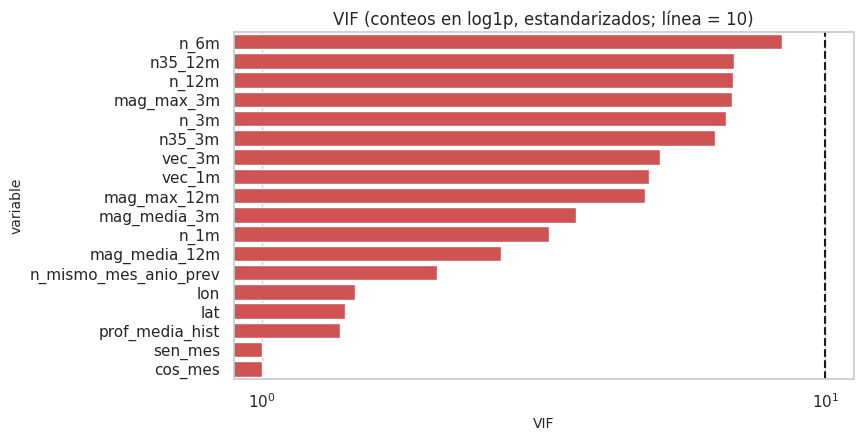

,variable,VIF
2,n_6m,8.37
5,n35_12m,6.88
3,n_12m,6.86
8,mag_max_3m,6.82
1,n_3m,6.66
4,n35_3m,6.38
12,vec_3m,5.09
11,vec_1m,4.86
9,mag_max_12m,4.79
6,mag_media_3m,3.61


In [12]:
# Multicolinealidad: factor de inflación de la varianza (VIF) de las predictoras estandarizadas
Z = L[X.columns].fillna(L[X.columns].median())
Z = (Z - Z.mean()) / Z.std()
v = pd.DataFrame({"variable": X.columns, "VIF": eda.vif(Z.to_numpy())}).sort_values("VIF", ascending=False)
eda.guardar_tabla(v, "vif.csv")
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.barplot(data=v, y="variable", x="VIF", color="#e53e3e", ax=ax); ax.axvline(10, ls="--", c="k"); ax.set_xscale("log")
ax.set_title("VIF (conteos en log1p, estandarizados; línea = 10)")
eda.guardar_figura(fig, "05_vif.png"); plt.show()
v.round(2)

In [13]:
md(f"""**Interpretación.**
- **Ninguna variable supera el umbral habitual de 10.** El máximo es `{v.variable.iloc[0]}` con VIF = {es(v.VIF.iloc[0], 1)}, y
  {int((v.VIF > 5).sum())} variables tienen colinealidad moderada (VIF entre 5 y 10).
- **Por qué no se eliminan.** Son ventanas anidadas del mismo conteo: `n_12m` contiene a `n_6m`, que contiene a `n_3m`.
  - La colinealidad **no sesga la predicción**; solo hace inestables los coeficientes individuales de un modelo lineal.
  - Como el objetivo es pronosticar y no interpretar cada coeficiente, se conservan.
  - El modelo base (SVR lineal) incluye regularización L2 a través de C, que estabiliza los coeficientes; su lectura en el
    capítulo 11 se hace por bloques y no variable por variable.""")

**Interpretación.**
- **Ninguna variable supera el umbral habitual de 10.** El máximo es `n_6m` con VIF = 8,4, y
  7 variables tienen colinealidad moderada (VIF entre 5 y 10).
- **Por qué no se eliminan.** Son ventanas anidadas del mismo conteo: `n_12m` contiene a `n_6m`, que contiene a `n_3m`.
  - La colinealidad **no sesga la predicción**; solo hace inestables los coeficientes individuales de un modelo lineal.
  - Como el objetivo es pronosticar y no interpretar cada coeficiente, se conservan.
  - El modelo base (SVR lineal) incluye regularización L2 a través de C, que estabiliza los coeficientes; su lectura en el
    capítulo 11 se hace por bloques y no variable por variable.